# 03 - Decision Tree và Random Forest trên Diabetes prediction dataset

Mục tiêu: dự đoán `diabetes` (0/1) trên bộ 100.000 dòng. Đây không phải bộ Pima; dữ liệu có mất cân bằng nên chọn model bằng ROC AUC và báo cáo thêm recall/F1 của lớp 1.

## 1. Load data và EDA ngắn

In [1]:
from pathlib import Path
import ast
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 24
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

NOTEBOOK_NAME = "03_diabetes_dt_rf"
DATASET_NAME = "diabetes"
df = pd.read_csv(DATA_DIR / "diabetes.csv")
print("Shape:", df.shape)
print("Số dòng trùng lặp:", int(df.duplicated().sum()))
print("Missing values:", int(df.isna().sum().sum()))
print("Phân bố target:")
display(df["diabetes"].value_counts(normalize=True).rename("proportion").to_frame())
display(df.head())


Shape: (100000, 9)
Số dòng trùng lặp: 3854
Missing values: 0
Phân bố target:


,proportion
diabetes,
0,0.915
1,0.085


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


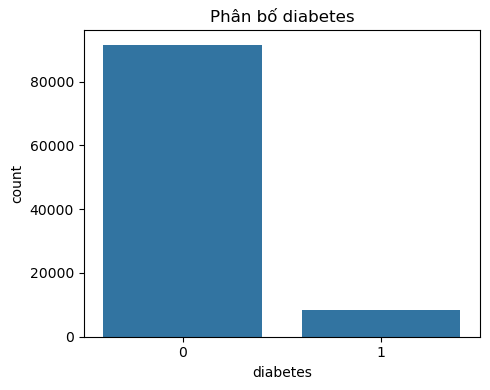

In [2]:
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="diabetes")
plt.title("Phân bố diabetes")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_diabetes_target_distribution.png", dpi=150)
plt.show()


## 2. Tiền xử lý và chia dữ liệu

In [3]:
data = df.drop_duplicates().copy()
print("Shape sau drop_duplicates:", data.shape)
target = "diabetes"
X = data.drop(columns=target)
y = data[target].astype(int)
categorical_features = ["gender", "smoking_history"]
numeric_features = ["age", "bmi", "HbA1c_level", "blood_glucose_level",
                    "hypertension", "heart_disease"]
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_features),
    ]
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train/test:", X_train.shape, X_test.shape)


Shape sau drop_duplicates: (96146, 9)
Train/test: (76916, 8) (19230, 8)


## 3. Tuning bằng cross-validation

In [4]:
dt_search = GridSearchCV(
    Pipeline([("preprocessor", preprocessor), ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    {
        "model__max_depth": [4, 8, 12, None],
        "model__min_samples_leaf": [1, 5, 20],
        "model__class_weight": [None, "balanced"],
    },
    scoring="roc_auc", cv=3, n_jobs=-1, return_train_score=True, error_score=np.nan
)
dt_search.fit(X_train, y_train)
print("Decision Tree best params:", dt_search.best_params_)
print("Decision Tree CV ROC AUC:", dt_search.best_score_)

rf_search = GridSearchCV(
    Pipeline([("preprocessor", preprocessor), ("model", RandomForestClassifier(
        random_state=RANDOM_STATE, n_jobs=-1
    ))]),
    {
        "model__n_estimators": [100],
        "model__max_depth": [None, 16],
        "model__min_samples_leaf": [1, 5],
        "model__class_weight": [None, "balanced"],
    },
    scoring="roc_auc", cv=3, n_jobs=-1, return_train_score=True, error_score=np.nan
)
rf_search.fit(X_train, y_train)
print("Random Forest best params:", rf_search.best_params_)
print("Random Forest CV ROC AUC:", rf_search.best_score_)


Decision Tree best params: {'model__class_weight': 'balanced', 'model__max_depth': 8, 'model__min_samples_leaf': 20}
Decision Tree CV ROC AUC: 0.9727761843829165


Random Forest best params: {'model__class_weight': 'balanced', 'model__max_depth': 16, 'model__min_samples_leaf': 5, 'model__n_estimators': 100}
Random Forest CV ROC AUC: 0.9744543302371875


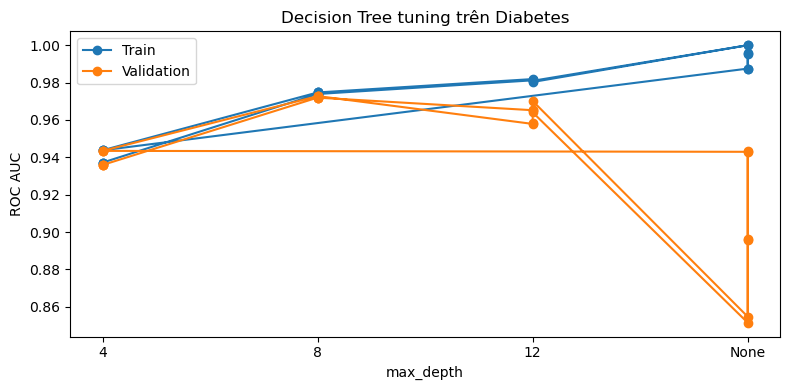

In [5]:
cv_results = pd.DataFrame(dt_search.cv_results_)
plt.figure(figsize=(8, 4))
plt.plot(cv_results["param_model__max_depth"].astype(str), cv_results["mean_train_score"], "o-", label="Train")
plt.plot(cv_results["param_model__max_depth"].astype(str), cv_results["mean_test_score"], "o-", label="Validation")
plt.xlabel("max_depth")
plt.ylabel("ROC AUC")
plt.title("Decision Tree tuning trên Diabetes")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "03_diabetes_dt_tuning.png", dpi=150)
plt.show()


## 4. Đánh giá trên tập test

In [6]:
def evaluate_model(name, estimator, X_test, y_test, feature_names, figure_prefix):
    y_pred = estimator.predict(X_test)
    y_score = estimator.predict_proba(X_test)[:, 1]
    metrics = {
        "notebook": NOTEBOOK_NAME,
        "dataset": DATASET_NAME,
        "model": name,
        "best_params": str(estimator.best_params_),
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_score),
    }
    print(f"\n{name} - classification report")
    print(classification_report(y_test, y_pred, zero_division=0))
    print(f"ROC AUC: {metrics['roc_auc']:.4f}")
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
    plt.title(f"{name} - confusion matrix")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{figure_prefix}_{name.lower().replace(' ', '_')}_confusion_matrix.png", dpi=150)
    plt.show()
    RocCurveDisplay.from_predictions(y_test, y_score, name=name)
    plt.title(f"{name} - ROC curve")
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{figure_prefix}_{name.lower().replace(' ', '_')}_roc_curve.png", dpi=150)
    plt.show()
    return metrics


def append_results(rows):
    results_path = FIG_DIR / "results_summary.csv"
    columns = ["notebook", "dataset", "model", "best_params", "accuracy",
               "precision", "recall", "f1", "roc_auc"]
    old_rows = []
    if results_path.exists():
        with results_path.open(newline="", encoding="utf-8") as file:
            old_rows = list(csv.DictReader(file))
    old_rows = [row for row in old_rows if row.get("notebook") != NOTEBOOK_NAME]
    with results_path.open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=columns)
        writer.writeheader()
        writer.writerows(old_rows)
        writer.writerows(rows)



DecisionTree - classification report
              precision    recall  f1-score   support

           0       0.99      0.87      0.93     17534
           1       0.42      0.93      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.90      0.75     19230
weighted avg       0.94      0.88      0.90     19230

ROC AUC: 0.9743


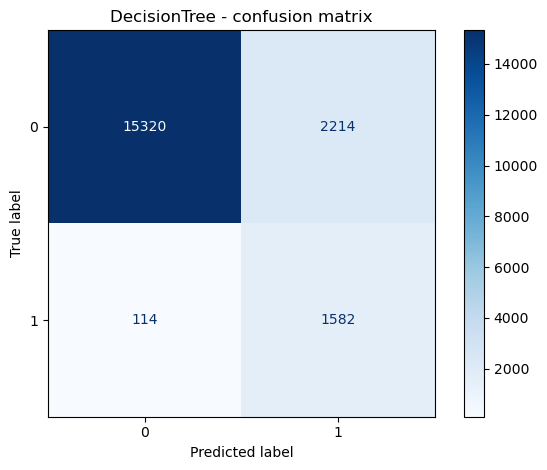

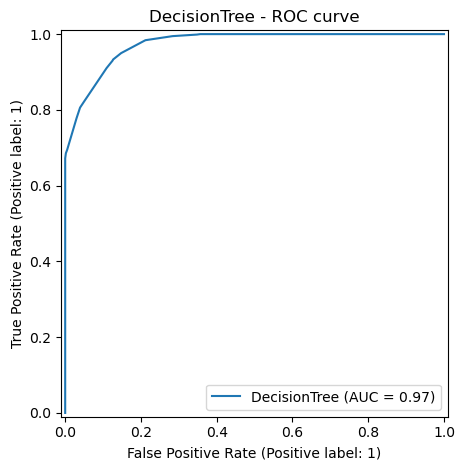


RandomForest - classification report
              precision    recall  f1-score   support

           0       0.99      0.94      0.96     17534
           1       0.58      0.85      0.69      1696

    accuracy                           0.93     19230
   macro avg       0.78      0.90      0.83     19230
weighted avg       0.95      0.93      0.94     19230

ROC AUC: 0.9772


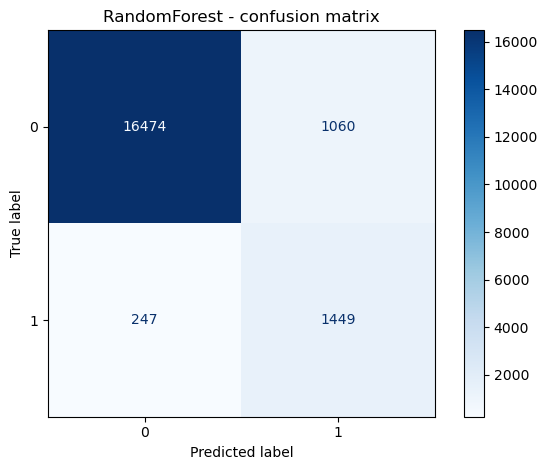

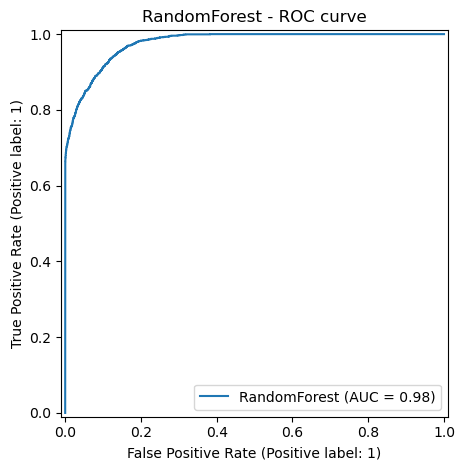

,model,accuracy,precision,recall,f1,roc_auc
0,DecisionTree,0.878939,0.416754,0.932783,0.576111,0.974286
1,RandomForest,0.932033,0.577521,0.854363,0.689180,0.977178


In [7]:
diabetes_results = [
    evaluate_model("DecisionTree", dt_search, X_test, y_test, None, "03_diabetes"),
    evaluate_model("RandomForest", rf_search, X_test, y_test, None, "03_diabetes"),
]
results = pd.DataFrame(diabetes_results)
display(results[["model", "accuracy", "precision", "recall", "f1", "roc_auc"]])


## 5. Feature importance và nhận xét

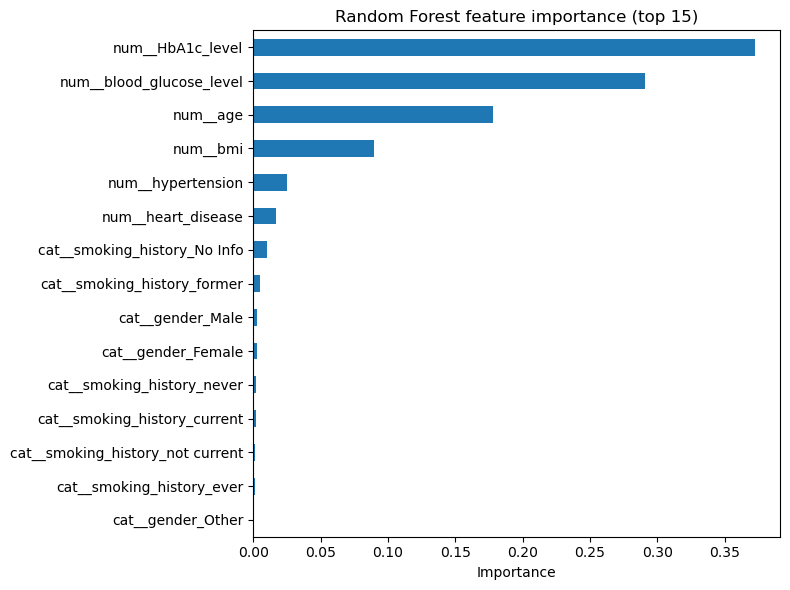

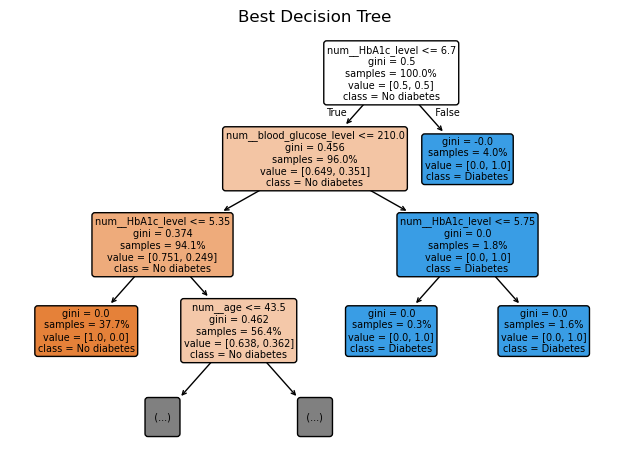

In [8]:
best_rf = rf_search.best_estimator_
feature_names = best_rf.named_steps["preprocessor"].get_feature_names_out()
importance = pd.Series(
    best_rf.named_steps["model"].feature_importances_, index=feature_names
).sort_values(ascending=True)
plt.figure(figsize=(8, 6))
importance.tail(15).plot.barh()
plt.title("Random Forest feature importance (top 15)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_diabetes_rf_feature_importance.png", dpi=150)
plt.show()

plot_tree(
    dt_search.best_estimator_.named_steps["model"],
    feature_names=dt_search.best_estimator_.named_steps["preprocessor"].get_feature_names_out(),
    class_names=["No diabetes", "Diabetes"],
    filled=True, rounded=True, max_depth=3, proportion=True, fontsize=7,
)
plt.title("Best Decision Tree")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_diabetes_best_tree.png", dpi=150)
plt.show()


Không xử lý các số 0 vì đây là Diabetes prediction dataset theo ghi đè, trong đó `hypertension` và `heart_disease` là biến nhị phân hợp lệ. Các biến số có giá trị đo lường thực tế; `gender` và `smoking_history` được OneHotEncoder. Do lớp 1 chỉ khoảng 8–9%, accuracy một mình không đủ; recall, F1 và ROC AUC quan trọng hơn. Nếu model dùng `class_weight='balanced'`, recall thường tăng nhưng precision/accuracy có thể giảm.

In [9]:
append_results(diabetes_results)
print("Đã cập nhật figures/results_summary.csv cho notebook 03.")


Đã cập nhật figures/results_summary.csv cho notebook 03.
